# Do our coffee promotions actually pay off?

**Author:** Shweta Kale

**Business question:** *Bean & Co.* (a fictional coffee brand) runs discounts on its four products
almost every month. Which promotions make money, which lose money, and what should we do next?

**Data:** simulated weekly sales for 4 products in 10 stores over 52 weeks (2025).
The data is simulated so that the method can be checked against known patterns
(see `generate_data.py`). Results are associations in simulated data, not proven causes.

| Step | Question |
|---|---|
| 0 | Is the data clean enough to use? |
| 1 | What do we normally sell (baseline)? |
| 2 | How much do discounts lift sales? |
| 3 | Do promotion weeks make more profit? |
| 4 | How price-sensitive is each product? |
| 5 | Do sales dip in the week after a promotion? |
| 6 | True profit of each promotion, and recommendation |
| 7 | Predicting sales for a planned promotion |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

pd.set_option("display.float_format", "{:,.2f}".format)

# Chart style: one colour per product, used the same way in every chart
COLORS = {"Budget": "#2a78d6", "Standard": "#eb6834", "Premium": "#1baf7a", "Pods": "#eda100"}
SEGMENTS = ["Budget", "Standard", "Premium", "Pods"]
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e6e5e0", "axes.axisbelow": True, "font.size": 11,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
})

sales = pd.read_csv("data/weekly_sales.csv", parse_dates=["week_start"])
products = pd.read_csv("data/products.csv")
stores = pd.read_csv("data/stores.csv")
products

,product_id,product_name,segment,regular_price,unit_cost
0,P1,Everyday Ground 500g,Budget,4.99,2.75
1,P2,Classic Beans 1kg,Standard,12.99,7.80
2,P3,Origin Premium 250g,Premium,8.99,4.05
3,P4,Coffee Pods 20-pack,Pods,5.49,2.75


## Step 0: Data check

In [2]:
print("Rows:", len(sales))
print("Missing values per column:")
print(sales.isna().sum())
print("Exact duplicate rows:", sales.duplicated().sum())
print("Prices <= 0:", (sales.price_paid <= 0).sum(), "| Negative units:", (sales.units_sold < 0).sum())

Rows: 2083
Missing values per column:
week_start      0
store_id        0
product_id      0
discount_pct    0
price_paid      0
units_sold      6
dtype: int64
Exact duplicate rows: 3
Prices <= 0: 0 | Negative units: 0


In [3]:
# Remove duplicates; drop the few rows with missing units (0.3% of data, too few to matter)
clean = sales.drop_duplicates().dropna(subset=["units_sold"]).copy()
print("Rows after cleaning:", len(clean))

df = (clean.merge(products, on="product_id").merge(stores, on="store_id")
           .sort_values(["store_id", "product_id", "week_start"]))

# Helper columns
df["prev_discount_pct"] = df.groupby(["store_id", "product_id"]).discount_pct.shift(1).fillna(0)
df["is_promo"] = df.discount_pct > 0
df["after_promo"] = (df.prev_discount_pct > 0) & (~df.is_promo)

def season(month):
    if month in (12, 1, 2): return "Winter"
    if month in (3, 4, 5):  return "Spring"
    if month in (6, 7, 8):  return "Summer"
    return "Autumn"
df["season"] = df.week_start.dt.month.map(season)

df["revenue"] = df.price_paid * df.units_sold
df["profit"] = (df.price_paid - df.unit_cost) * df.units_sold
df.head()

Rows after cleaning: 2074


,week_start,store_id,product_id,discount_pct,price_paid,units_sold,product_name,segment,regular_price,unit_cost,city,store_size,prev_discount_pct,is_promo,after_promo,season,revenue,profit
0,2025-01-06,S01,P1,0,4.99,209.00,Everyday Ground 500g,Budget,4.99,2.75,Cologne,Large,0.00,False,False,Winter,"1,042.91",468.16
40,2025-01-13,S01,P1,0,4.99,226.00,Everyday Ground 500g,Budget,4.99,2.75,Cologne,Large,0.00,False,False,Winter,"1,127.74",506.24
80,2025-01-20,S01,P1,20,3.99,416.00,Everyday Ground 500g,Budget,4.99,2.75,Cologne,Large,0.00,True,False,Winter,"1,659.84",515.84
119,2025-01-27,S01,P1,0,4.99,168.00,Everyday Ground 500g,Budget,4.99,2.75,Cologne,Large,20.00,False,True,Winter,838.32,376.32
159,2025-02-03,S01,P1,0,4.99,222.00,Everyday Ground 500g,Budget,4.99,2.75,Cologne,Large,0.00,False,False,Winter,"1,107.78",497.28


**Finding:** 3 duplicate rows and 6 missing values, removed. No impossible prices or units.
In real client data this step usually takes much longer.

## Step 1: Baseline (what we normally sell)

"Normal weeks" = no discount **and** not the week right after a discount (that week can be distorted, see Step 5).
Sales also change with the season, so we compare **like with like**: each store, product and season gets its own baseline.

In [4]:
normal = df[~df.is_promo & ~df.after_promo]
baseline = (normal.groupby(["store_id", "product_id", "season"])
                  .agg(base_units=("units_sold", "mean"), base_profit=("profit", "mean"))
                  .reset_index())
df = df.merge(baseline, on=["store_id", "product_id", "season"], how="left")

summary = (normal.groupby("segment")
                 .agg(avg_units_per_store_week=("units_sold", "mean"),
                      avg_profit_per_store_week=("profit", "mean"))
                 .reindex(SEGMENTS))
summary

,avg_units_per_store_week,avg_profit_per_store_week
segment,,
Budget,138.60,310.47
Standard,49.51,256.96
Premium,35.54,175.58
Pods,80.70,221.12


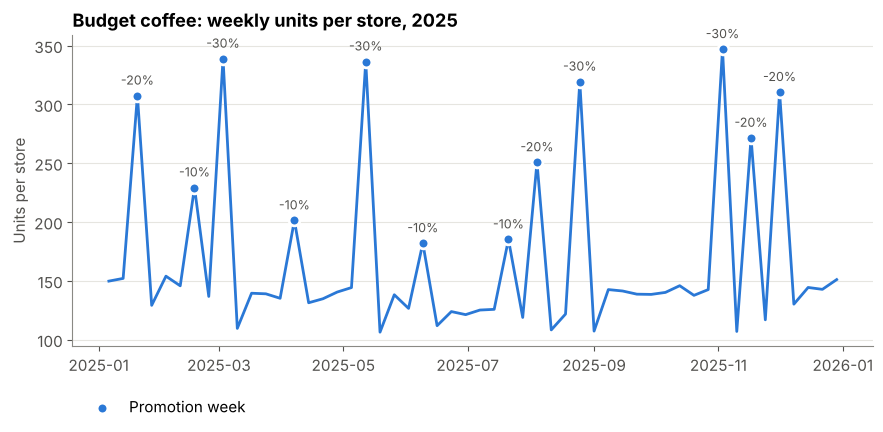

In [5]:
# What one year looks like for the budget product (average over stores)
one = df[df.segment == "Budget"].groupby("week_start").agg(units=("units_sold", "mean"),
                                                             disc=("discount_pct", "first"))
fig, ax = plt.subplots()
ax.plot(one.index, one.units, color=COLORS["Budget"], lw=2)
promo = one[one.disc > 0]
ax.scatter(promo.index, promo.units, color=COLORS["Budget"], s=60, zorder=3,
           edgecolor="white", linewidth=2, label="Promotion week")
for d, row in promo.iterrows():
    ax.annotate(f"-{int(row.disc)}%", (d, row.units), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9, color="#52514e")
ax.set_title("Budget coffee: weekly units per store, 2025")
ax.set_ylabel("Units per store")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.12))
plt.tight_layout(); plt.savefig("charts/01_budget_weekly.png", dpi=160); plt.show()

Each spike is a promotion. Notice the small drop in the week right after many spikes (Step 5).

## Step 2: Sales uplift from discounts

Uplift = units in promo weeks ÷ baseline units (same store, product, season) − 1.

In [6]:
promo = df[df.is_promo]
agg = promo.groupby(["segment", "discount_pct"])[["units_sold", "base_units", "profit", "base_profit"]].sum()
agg["uplift_pct"] = (agg.units_sold / agg.base_units - 1) * 100
uplift = agg["uplift_pct"].unstack().reindex(SEGMENTS)
uplift.columns = [f"{c}% off" for c in uplift.columns]
uplift.round(0)

,10% off,20% off,30% off
segment,,,
Budget,49.00,103.00,147.00
Standard,34.00,69.00,100.00
Premium,10.00,18.00,31.00
Pods,44.00,83.00,136.00


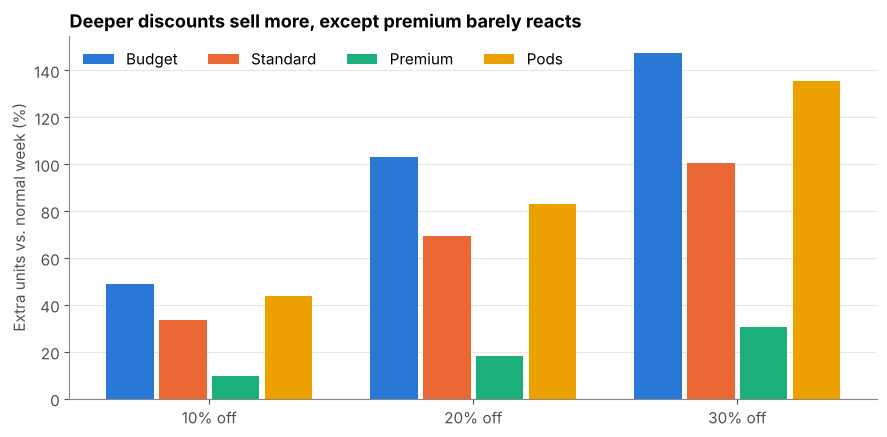

In [7]:
fig, ax = plt.subplots()
x = np.arange(3); w = 0.2
for i, seg in enumerate(SEGMENTS):
    vals = uplift.loc[seg].values
    bars = ax.bar(x + (i - 1.5) * w, vals, w - 0.02, color=COLORS[seg], label=seg)
ax.set_xticks(x, ["10% off", "20% off", "30% off"])
ax.set_ylabel("Extra units vs. normal week (%)")
ax.set_title("Deeper discounts sell more, except premium barely reacts")
ax.legend(frameon=False, ncol=4, loc="upper left")
plt.tight_layout(); plt.savefig("charts/02_uplift.png", dpi=160); plt.show()

## Step 3: Profit in the promotion week

Selling more does not automatically mean earning more: every unit now earns less.
Profit change = profit in promo weeks ÷ baseline profit − 1.

In [8]:
agg["promo_week_profit_change_pct"] = (agg.profit / agg.base_profit - 1) * 100
pw_profit = agg["promo_week_profit_change_pct"].unstack().reindex(SEGMENTS)
pw_profit.columns = [f"{c}% off" for c in pw_profit.columns]
pw_profit.round(0)

,10% off,20% off,30% off
segment,,,
Budget,16.00,12.00,-18.00
Standard,0.00,-15.00,-50.00
Premium,-10.00,-25.00,-41.00
Pods,15.00,9.00,-6.00


**Finding:** Budget and Pods earn **more** profit at 10% and 20% off. Standard is break-even at 10%.
Premium **loses** profit at every discount level. All products lose money at 30% off.

## Step 4: Price sensitivity

Simple price sensitivity = % change in units ÷ % change in price.
Example: 10% discount and +50% units → sensitivity of 5. (Economists call the negative version *price elasticity*.)

In [9]:
agg["sensitivity"] = agg.uplift_pct / agg.index.get_level_values("discount_pct")
sens = agg["sensitivity"].unstack().reindex(SEGMENTS)
sens.columns = [f"{c}% off" for c in sens.columns]
sens["Average"] = sens.mean(axis=1)
sens.round(1)

,10% off,20% off,30% off,Average
segment,,,,
Budget,4.90,5.10,4.90,5.00
Standard,3.40,3.50,3.30,3.40
Premium,1.00,0.90,1.00,1.00
Pods,4.40,4.10,4.50,4.40


**Finding:** sensitivity is stable across discount levels for each product, so one number per product describes it well.
Budget customers react 5× more strongly than premium customers. Premium buyers are loyal to the product, not the price,
so discounting premium mostly gives away margin.

*Check against the simulation:* built-in values were Budget 5.0, Standard 3.5, Premium 1.0, Pods 4.5. The simple method recovers them closely.

## Step 5: The week after a promotion

If customers stock up during a discount, they buy less the following week. Those "lost" sales were only moved earlier, not created.

In [10]:
after = df[df.after_promo]
after = after.assign(prev_discount_pct=after.prev_discount_pct.astype(int))
aagg = after.groupby(["segment", "prev_discount_pct"])[["units_sold", "base_units", "profit", "base_profit"]].sum()
aagg.index.names = ["segment", "discount_pct"]
aagg["dip_pct"] = (aagg.units_sold / aagg.base_units - 1) * 100
dip = aagg["dip_pct"].unstack().reindex(SEGMENTS)
dip.columns = [f"after {c}% off" for c in dip.columns]
dip.round(0)

,after 10% off,after 20% off,after 30% off
segment,,,
Budget,-6.00,-14.00,-23.00
Standard,-5.00,-8.00,-11.00
Premium,1.00,-1.00,-1.00
Pods,-7.00,-14.00,-22.00


**Finding:** after a 30% discount, Budget and Pods sell about 20% less the next week. Premium shows no dip:
its buyers do not stockpile.

## Step 6: True profit of each promotion, and recommendation

True profit effect = (extra profit in the promo week) + (lost profit in the week after), compared with a normal week.
Shown in € per store per promotion.

In [11]:
total = agg[["profit", "base_profit"]].copy()
total["promo_week_gain"] = agg.profit - agg.base_profit
total["after_week_loss"] = aagg.profit - aagg.base_profit
n_obs = promo.groupby(["segment", "discount_pct"]).size()          # store-weeks per cell
total["net_eur_per_store"] = (total.promo_week_gain + total.after_week_loss) / n_obs
net = total["net_eur_per_store"].unstack().reindex(SEGMENTS)
net.columns = [f"{c}% off" for c in net.columns]
net.round(0)

,10% off,20% off,30% off
segment,,,
Budget,30.00,-5.00,-128.00
Standard,-12.00,-65.00,-159.00
Premium,-16.00,-43.00,-75.00
Pods,19.00,-10.00,-66.00


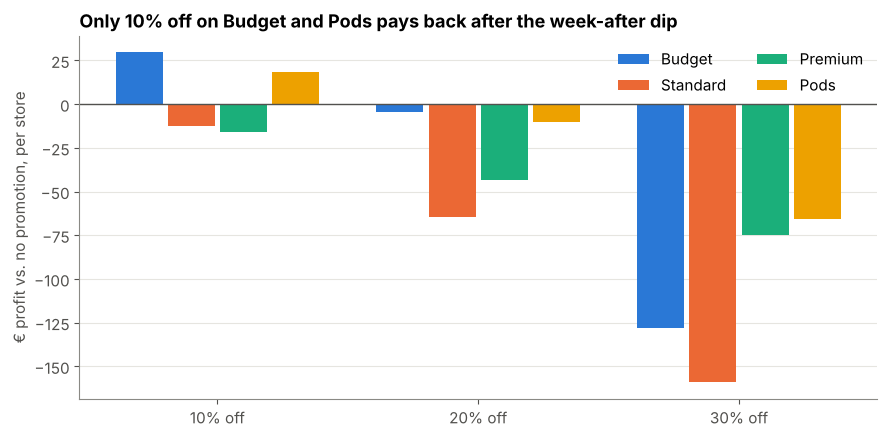

In [12]:
fig, ax = plt.subplots()
for i, seg in enumerate(SEGMENTS):
    vals = net.loc[seg].values
    ax.bar(x + (i - 1.5) * w, vals, w - 0.02, color=COLORS[seg], label=seg)
ax.axhline(0, color="#52514e", lw=1)
ax.set_xticks(x, ["10% off", "20% off", "30% off"])
ax.set_ylabel("€ profit vs. no promotion, per store")
ax.set_title("Only 10% off on Budget and Pods pays back after the week-after dip")
ax.legend(frameon=False, ncol=2, loc="upper right")
plt.tight_layout(); plt.savefig("charts/03_true_profit.png", dpi=160); plt.show()

In [13]:
# What did this year's promotion plan cost or earn in total? (all stores, all promotions)
plan = (total.promo_week_gain + total.after_week_loss).groupby("segment").sum().reindex(SEGMENTS)
print("Net profit effect of 2025 promotions, all stores (€):")
print(plan.round(0))
print("Total:", round(plan.sum()))

Net profit effect of 2025 promotions, all stores (€):
segment
Budget     -4,112.00
Standard   -9,441.00
Premium    -5,277.00
Pods       -2,282.00
dtype: float64
Total: -21113


**Finding:** across all stores, the 2025 promotion plan **lost about €21,000 in profit** compared with running no promotions at all.
Every product's plan was negative overall, mainly because of the 20% and 30% discounts.

### Recommendation

1. **Keep 10% discounts on Budget and Pods.** They are the only promotions that still earn money after the week-after dip.
2. **Stop 30% discounts on all products.** They create big volume spikes but lose the most money.
3. **Stop discounting Premium.** Its buyers barely react to price; use other levers (visibility, bundles, new flavours).
4. **20% off on Budget looks profitable in the promo week (+12%) but is break-even once the dip is included.** This is the key lesson: judge promotions over two weeks, not one.

### How to test it
Run the new plan in **3 stores** for 3 months, keep **3 similar stores** on the old plan as a control group,
and compare profit per store. Pick test and control stores with similar size and sales level.

### What I would check in real data
- **Competitor prices and promotions** in the same weeks
- **Cannibalisation:** does a discount on Budget take sales from our own Standard product?
- **Holidays and events**, beyond simple seasons
- **Sample size:** here each cell is 4 promotions × 10 stores; real decisions need enough repeats

## Step 7: Predicting sales for a planned promotion

**Question:** *"If we run 20% off Budget coffee in a large store in winter, how many units will we sell?"*

**Model:** one simple **linear regression per product**. It learns how many units each factor adds or removes:
discount %, discount % last week (the dip), store size, and season.

**Evaluation:**
- Train on weeks 1–39 (Jan–Sep), test on weeks 40–52 (Oct–Dec): we predict the future from the past, like in real life.
- Compare with a **simple baseline**: "predict the average sales of that product in that store".
- Error metric: **MAE** = on average, how many units the prediction is off.

In [14]:
model_df = df.copy()
model_df["week_no"] = model_df.groupby(["store_id", "product_id"]).cumcount() + 1
model_df["large_store"] = (model_df.store_size == "Large").astype(int)
model_df = pd.get_dummies(model_df, columns=["season"], drop_first=True, dtype=int)  # Autumn = reference
FEATURES = ["discount_pct", "prev_discount_pct", "large_store",
            "season_Spring", "season_Summer", "season_Winter"]

results, models = [], {}
for seg in SEGMENTS:
    d = model_df[model_df.segment == seg]
    train, test = d[d.week_no <= 39], d[d.week_no > 39]

    m = LinearRegression().fit(train[FEATURES], train.units_sold)
    models[seg] = m
    pred = m.predict(test[FEATURES])

    naive = test.store_id.map(train.groupby("store_id").units_sold.mean())

    results.append({"segment": seg,
                    "avg_units": test.units_sold.mean(),
                    "MAE_baseline": mean_absolute_error(test.units_sold, naive),
                    "MAE_model": mean_absolute_error(test.units_sold, pred)})

res = pd.DataFrame(results).set_index("segment")
res["improvement_pct"] = (1 - res.MAE_model / res.MAE_baseline) * 100
res["model_error_pct_of_sales"] = res.MAE_model / res.avg_units * 100
res.round(1)

,avg_units,MAE_baseline,MAE_model,improvement_pct,model_error_pct_of_sales
segment,,,,,
Budget,175.80,54.50,20.70,62.10,11.80
Standard,58.00,11.60,5.60,51.70,9.70
Premium,38.40,4.10,3.50,13.10,9.20
Pods,107.40,35.00,11.60,66.70,10.80


**Reading the result:** the model cuts the error by 50–67% for Budget, Standard and Pods, because it knows when a promotion is running.
For Premium the gain is small (13%): premium sales barely react to promotions, so there is little extra to predict.
The remaining error is mostly normal week-to-week noise and the fact that each store has its own sales level.

In [15]:
# What the model learned (units per store per week)
coefs = pd.DataFrame({seg: pd.Series(models[seg].coef_, index=FEATURES) for seg in SEGMENTS})
coefs.loc["intercept"] = [models[s].intercept_ for s in SEGMENTS]
coefs.round(2)

,Budget,Standard,Premium,Pods
discount_pct,6.70,1.75,0.32,3.56
prev_discount_pct,-0.98,-0.21,-0.03,-0.58
large_store,73.41,25.72,16.70,40.26
season_Spring,-1.56,-0.62,0.63,-0.91
season_Summer,-17.32,-6.18,-2.84,-9.50
season_Winter,15.05,5.60,4.08,7.33
intercept,110.24,40.83,28.11,66.56


Example of reading one number: for Budget, `discount_pct` ≈ 6.7 means each extra 1% discount adds about 7 units per store per week.
`prev_discount_pct` is negative: the dip after a promotion.

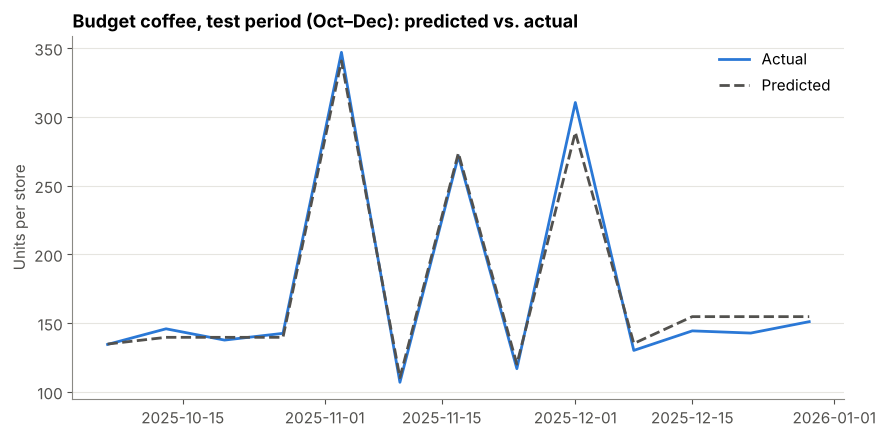

In [16]:
# Test period: actual vs. predicted, Budget, averaged over stores
seg = "Budget"
d = model_df[(model_df.segment == seg) & (model_df.week_no > 39)].copy()
d["pred"] = models[seg].predict(d[FEATURES])
wk = d.groupby("week_start")[["units_sold", "pred"]].mean()
fig, ax = plt.subplots()
ax.plot(wk.index, wk.units_sold, color=COLORS[seg], lw=2, label="Actual")
ax.plot(wk.index, wk.pred, color="#52514e", lw=2, ls="--", label="Predicted")
ax.set_title("Budget coffee, test period (Oct–Dec): predicted vs. actual")
ax.set_ylabel("Units per store")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("charts/04_prediction.png", dpi=160); plt.show()

In [17]:
# Answering the business question with the model
def what_if(segment, discount, large_store=1, season="Winter"):
    row = {f: 0 for f in FEATURES}
    row.update(discount_pct=discount, large_store=large_store)
    if season != "Autumn":
        row[f"season_{season}"] = 1
    units = models[segment].predict(pd.DataFrame([row]))[0]
    p = products.set_index("segment").loc[segment]
    price = p.regular_price * (1 - discount / 100)
    return pd.Series({"units": units, "revenue_eur": units * price,
                      "profit_eur": units * (price - p.unit_cost)})

pd.DataFrame({f"{d}% off": what_if("Budget", d) for d in [0, 10, 20, 30]}).T.round(0)

,units,revenue_eur,profit_eur
0% off,199.00,992.00,445.00
10% off,266.00,"1,193.00",463.00
20% off,333.00,"1,328.00",413.00
30% off,400.00,"1,396.00",297.00


**Reading it:** for a large store in winter, 10% off gives the highest promo-week profit; 20% and 30% sell more but earn less.
This is only the promo week: Step 6 showed we must also subtract the dip in the week after.

**Limitations:** the data is simulated and clean, so real accuracy would be lower. With real data I would add
store-level effects, holidays and competitor prices, and check the error per store before using the model for decisions.
A linear model was chosen on purpose: it is easy to explain to commercial teams, which matters for pricing decisions.